In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
MODEL_PATH = PROJECT_ROOT / "models/swin_tiny_epoch3.pth"

print("Checkpoint:", MODEL_PATH)
print("Exists:", MODEL_PATH.exists())

if MODEL_PATH.exists():
    print(f"Size: {MODEL_PATH.stat().st_size / (1024**2):.1f} MB")

Checkpoint: C:\Users\spgai\OneDrive\Documents\NetraDrishti\models\swin_tiny_epoch3.pth
Exists: True
Size: 315.4 MB


In [2]:
import torch

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu"
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print(" -", key)
else:
    print("\nCheckpoint is not a dictionary.")

Checkpoint type: <class 'dict'>

Checkpoint keys:
 - epoch
 - model_state_dict
 - optimizer_state_dict
 - train_loss
 - train_acc
 - val_loss
 - val_acc
 - class_to_idx


In [3]:
import torch
import torch.nn as nn
from torchvision.models import swin_t

# Recreate the same Swin-Tiny architecture
model = swin_t(weights=None)

# Replace ImageNet classification head with our 4-class OCT head
model.head = nn.Linear(model.head.in_features, 4)

# Load trained weights
state_dict = checkpoint["model_state_dict"]
load_result = model.load_state_dict(state_dict)

# Evaluation mode
model.eval()

print("Model loaded successfully.")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

print("\nClass mapping:")
print(checkpoint["class_to_idx"])

print("\nSaved training information:")
print("Epoch:", checkpoint["epoch"])
print("Train accuracy:", checkpoint["train_acc"])
print("Validation accuracy:", checkpoint["val_acc"])

Model loaded successfully.
Missing keys: []
Unexpected keys: []

Class mapping:
{'CNV': 0, 'DME': 1, 'DRUSEN': 2, 'NORMAL': 3}

Saved training information:
Epoch: 3
Train accuracy: 0.9641970495906769
Validation accuracy: 0.9502400295420975


In [4]:
# Final spatial feature layer used before classification
target_layer = model.norm

print("Grad-CAM target layer:")
print(target_layer)

Grad-CAM target layer:
LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)


In [5]:
import torch
import torch.nn.functional as F


class SwinGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(
            self._save_activation
        )

        self.backward_handle = target_layer.register_full_backward_hook(
            self._save_gradient
        )

    def _save_activation(self, module, inputs, output):
        self.activations = output

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, input_tensor, class_idx=None):
        self.model.zero_grad(set_to_none=True)

        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        score = output[:, class_idx]
        score.backward()

        # Swin output from model.norm:
        # [batch, height, width, channels]
        activations = self.activations
        gradients = self.gradients

        # Global-average-pool gradients over spatial dimensions
        weights = gradients.mean(dim=(1, 2), keepdim=True)

        # Weighted combination of feature channels
        cam = (weights * activations).sum(dim=-1)

        # ReLU: retain regions positively supporting the target class
        cam = F.relu(cam)

        # Normalize each heatmap to [0, 1]
        cam_min = cam.flatten(1).min(dim=1)[0].view(-1, 1, 1)
        cam_max = cam.flatten(1).max(dim=1)[0].view(-1, 1, 1)

        cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)

        return cam.detach(), output.detach(), class_idx

    def remove_hooks(self):
        self.forward_handle.remove()
        self.backward_handle.remove()


gradcam = SwinGradCAM(model, target_layer)

print("Swin Grad-CAM engine ready.")

Swin Grad-CAM engine ready.


In [6]:
from pathlib import Path

OCT_ROOT = PROJECT_ROOT / "oct"

# Find the first OCT image in the validation/test data
image_files = list(OCT_ROOT.rglob("*.jpeg"))

print("Images found:", len(image_files))

if image_files:
    print("Example:", image_files[0])

Images found: 109310
Example: C:\Users\spgai\OneDrive\Documents\NetraDrishti\oct\test\CNV\CNV-1032178-1.jpeg


In [7]:
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import torch

IMG_SIZE = 256

imagenet_normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)


def preprocess_oct(image):
    image = image.convert("L")
    
    # Preserve aspect ratio
    image.thumbnail((IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS)
    
    tensor = transforms.ToTensor()(image)
    tensor = imagenet_normalize(tensor.repeat(3, 1, 1))
    
    # Center padding
    padded = torch.zeros((3, IMG_SIZE, IMG_SIZE))
    
    h, w = tensor.shape[1:]
    y = (IMG_SIZE - h) // 2
    x = (IMG_SIZE - w) // 2
    
    padded[:, y:y+h, x:x+w] = tensor
    
    return padded


# Select one image
image_path = image_files[0]

# Load image
original_image = Image.open(image_path).convert("L")

# Preprocess
input_tensor = preprocess_oct(original_image).unsqueeze(0)

# Generate Grad-CAM
cam, output, predicted_idx = gradcam.generate(input_tensor)

# Convert prediction to probabilities
probabilities = torch.softmax(output, dim=1)[0]

idx_to_class = {v: k for k, v in checkpoint["class_to_idx"].items()}

predicted_class = idx_to_class[predicted_idx]
confidence = probabilities[predicted_idx].item()

print("Image:", image_path.name)
print("True class:", image_path.parent.name)
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.4f}")
print("CAM shape:", cam.shape)

Image: CNV-1032178-1.jpeg
True class: CNV
Predicted class: CNV
Confidence: 0.9914
CAM shape: torch.Size([1, 8, 8])


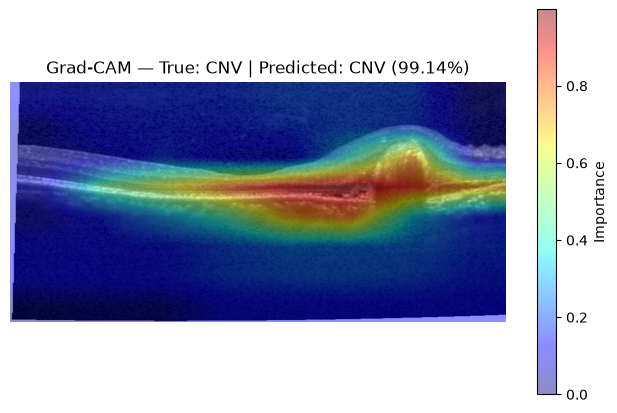

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

# Upscale Grad-CAM from 8x8 to the original image size
cam_up = F.interpolate(
    cam.unsqueeze(1),
    size=original_image.size[::-1],
    mode="bilinear",
    align_corners=False
)[0, 0].cpu().numpy()

# Normalize original image for display
original_np = np.array(original_image).astype(np.float32)
original_np = (original_np - original_np.min()) / (
    original_np.max() - original_np.min() + 1e-8
)

plt.figure(figsize=(8, 5))

plt.imshow(original_np, cmap="gray")
plt.imshow(cam_up, cmap="jet", alpha=0.45)

plt.title(
    f"Grad-CAM — True: {image_path.parent.name} | "
    f"Predicted: {predicted_class} ({confidence:.2%})"
)

plt.axis("off")
plt.colorbar(label="Importance")
plt.show()

In [9]:
print("Activation shape:", gradcam.activations.shape)
print("Gradient shape:", gradcam.gradients.shape)
print("CAM shape:", cam.shape)

Activation shape: torch.Size([1, 8, 8, 768])
Gradient shape: torch.Size([1, 8, 8, 768])
CAM shape: torch.Size([1, 8, 8])


In [10]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image


def show_gradcam(image_path):

    # -----------------------------
    # 1. Load original OCT image
    # -----------------------------
    original_image = Image.open(image_path).convert("L")

    # -----------------------------
    # 2. Preprocess image
    # -----------------------------
    input_tensor = preprocess_oct(original_image).unsqueeze(0)

    # -----------------------------
    # 3. Generate Grad-CAM
    # -----------------------------
    cam, output, predicted_idx = gradcam.generate(input_tensor)

    # -----------------------------
    # 4. Get prediction probability
    # -----------------------------
    probabilities = torch.softmax(output, dim=1)[0]

    predicted_class = idx_to_class[predicted_idx]
    confidence = probabilities[predicted_idx].item() * 100

    # -----------------------------
    # 5. Resize CAM to image size
    # -----------------------------
    cam_up = torch.nn.functional.interpolate(
        cam.unsqueeze(1),
        size=(256, 256),
        mode="bilinear",
        align_corners=False
    )[0, 0].cpu().numpy()

    # Normalize CAM
    cam_up = (cam_up - cam_up.min()) / (
        cam_up.max() - cam_up.min() + 1e-8
    )

    # -----------------------------
    # 6. Prepare original image
    # -----------------------------
    original = np.array(
        original_image.resize((256, 256))
    )

    # Convert grayscale → RGB
    original_rgb = cv2.cvtColor(
        original,
        cv2.COLOR_GRAY2RGB
    )

    # -----------------------------
    # 7. Create heatmap
    # -----------------------------
    heatmap = cv2.applyColorMap(
        np.uint8(255 * cam_up),
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )

    # -----------------------------
    # 8. Create overlay
    # -----------------------------
    overlay = cv2.addWeighted(
        original_rgb,
        0.6,
        heatmap,
        0.4,
        0
    )

    # -----------------------------
    # 9. Display results
    # -----------------------------
    plt.figure(figsize=(15, 5))

    # Original
    plt.subplot(1, 3, 1)
    plt.imshow(original, cmap="gray")
    plt.title("Original OCT")
    plt.axis("off")

    # Heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap)
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    # Overlay
    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [11]:
import os
print(os.getcwd())

C:\Users\spgai\OneDrive\Documents\NetraDrishti\notebooks


In [12]:
print(os.listdir())

['.ipynb_checkpoints', 'EDA.ipynb', 'Grad_Cam.ipynb']


In [13]:
import os

for root, dirs, files in os.walk("."):
    if "CNV-14999-1.jpeg" in files:
        print(os.path.join(root, "CNV-14999-1.jpeg"))

In [14]:
from torchvision import transforms

preprocess = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

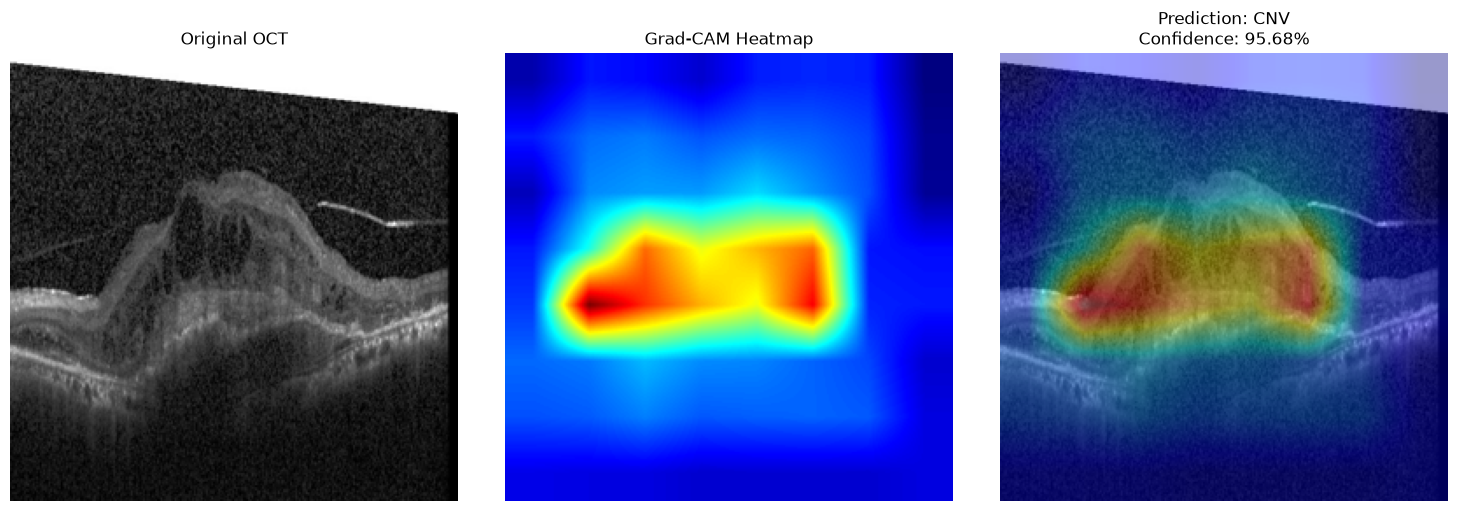

In [15]:
show_gradcam(r"C:\Users\spgai\OneDrive\Documents\NetraDrishti\OCT\test\CNV\CNV-1569-1.jpeg")

In [16]:
from pathlib import Path

TEST_ROOT = PROJECT_ROOT / "oct" / "test"

classes = ["CNV", "DME", "DRUSEN", "NORMAL"]

class_images = {}

for class_name in classes:
    class_dir = TEST_ROOT / class_name

    # Take only the first image we find
    image = next(class_dir.glob("*.jpeg"), None)

    if image is not None:
        class_images[class_name] = image

print("Selected images:")

for class_name, image_path in class_images.items():
    print(f"{class_name}: {image_path.name}")

Selected images:
CNV: CNV-1032178-1.jpeg
DME: DME-1029576-1.jpeg
DRUSEN: DRUSEN-1021298-1.jpeg
NORMAL: NORMAL-100980-1.jpeg


In [17]:
print(type(gradcam))
print(type(preprocess_oct))

<class '__main__.SwinGradCAM'>
<class 'function'>


In [18]:
def validate_gradcam(class_images):

    results = []

    for true_class, image_path in class_images.items():

        original_image = Image.open(image_path).convert("L")
        input_tensor = preprocess_oct(original_image).unsqueeze(0)

        # Generate Grad-CAM
        cam, output, predicted_idx = gradcam.generate(input_tensor)

        # Prediction probability
        probabilities = torch.softmax(output, dim=1)[0]
        predicted_class = idx_to_class[predicted_idx]
        confidence = probabilities[predicted_idx].item()

        # Resize Grad-CAM to original image dimensions
        cam_up = F.interpolate(
            cam.unsqueeze(1),
            size=original_image.size[::-1],
            mode="bilinear",
            align_corners=False
        )[0, 0].cpu().numpy()

        results.append({
            "True Class": true_class,
            "Predicted Class": predicted_class,
            "Confidence": confidence,
            "Image": image_path.name,
            "CAM": cam_up
        })

        # Display
        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(original_image, cmap="gray")
        plt.title(f"Original\nTrue: {true_class}")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(cam_up, cmap="jet")
        plt.title("Grad-CAM Heatmap")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(original_image, cmap="gray")
        plt.imshow(cam_up, cmap="jet", alpha=0.45)
        plt.title(
            f"Predicted: {predicted_class}\n"
            f"Confidence: {confidence:.2%}"
        )
        plt.axis("off")

        plt.tight_layout()
        plt.show()

    return results

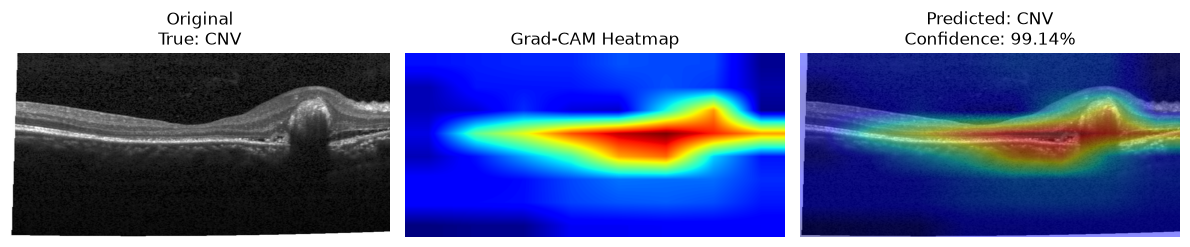

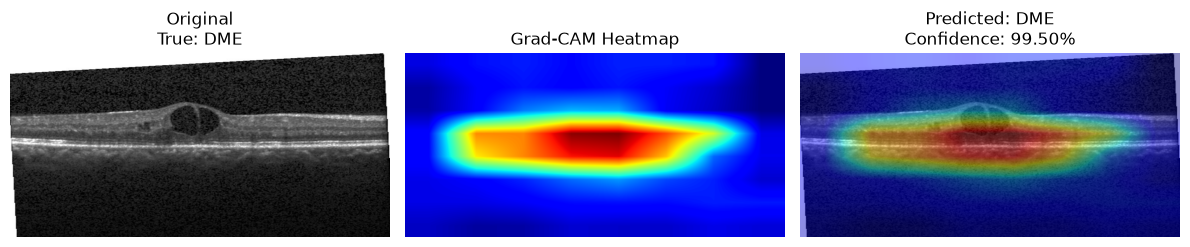

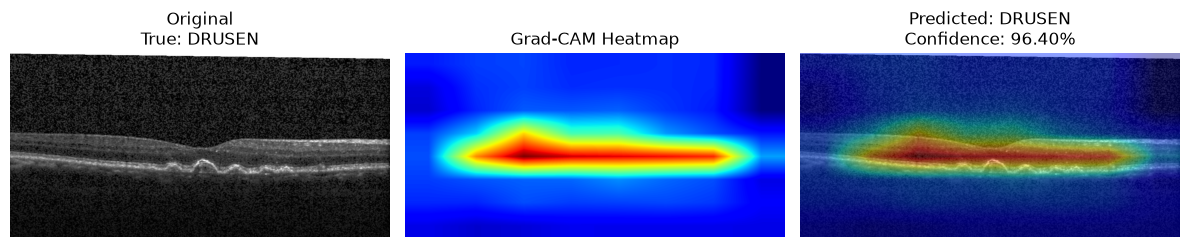

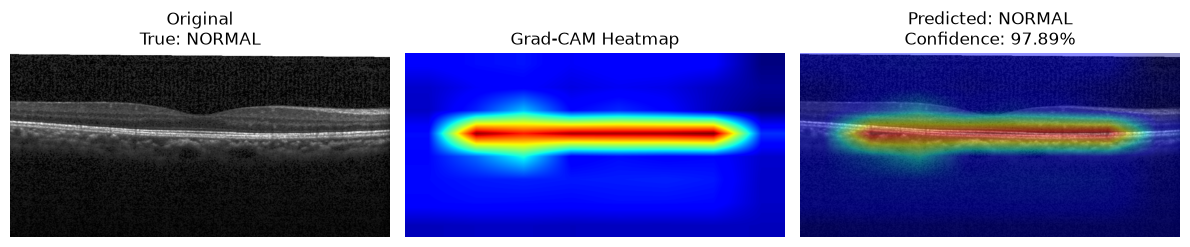

In [19]:
results = validate_gradcam(class_images)

In [20]:
print("Available evaluation-related variables:")

for name in ["train_loader", "val_loader", "test_loader",
             "train_dataset", "val_dataset", "test_dataset",
             "class_names", "idx_to_class", "class_to_idx"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

Available evaluation-related variables:
idx_to_class: dict


In [21]:
for name, value in list(globals().items()):
    if any(word in name.lower() for word in ["data", "dataset", "loader", "test", "val", "train"]):
        print(name, "→", type(value).__name__)

__loader__ → NoneType
TEST_ROOT → WindowsPath
validate_gradcam → function


In [22]:
from pathlib import Path

print("Test directory:", TEST_ROOT)

for class_dir in sorted(TEST_ROOT.iterdir()):
    if class_dir.is_dir():
        print(f"{class_dir.name}: {len(list(class_dir.glob('*')))} images")

Test directory: C:\Users\spgai\OneDrive\Documents\NetraDrishti\oct\test
CNV: 251 images
DME: 250 images
DRUSEN: 250 images
NORMAL: 250 images


In [23]:
print("Model class mapping:")
print(idx_to_class)

Model class mapping:
{0: 'CNV', 1: 'DME', 2: 'DRUSEN', 3: 'NORMAL'}


In [24]:
from torchvision import datasets

test_dataset = datasets.ImageFolder(
    root=TEST_ROOT,
    transform=preprocess_oct
)

print("Number of test images:", len(test_dataset))
print("Test class mapping:", test_dataset.class_to_idx)

Number of test images: 1001
Test class mapping: {'CNV': 0, 'DME': 1, 'DRUSEN': 2, 'NORMAL': 3}


In [25]:
print("test_dataset" in globals())

if "test_dataset" in globals():
    print(type(test_dataset))
    print("Number of images:", len(test_dataset))
    print("Class mapping:", test_dataset.class_to_idx)

True
<class 'torchvision.datasets.folder.ImageFolder'>
Number of images: 1001
Class mapping: {'CNV': 0, 'DME': 1, 'DRUSEN': 2, 'NORMAL': 3}


In [26]:
from torch.utils.data import DataLoader

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Number of test batches:", len(test_loader))

Number of test batches: 32


In [27]:
images, labels = next(iter(test_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in first batch:", labels.tolist())

Image batch shape: torch.Size([32, 3, 256, 256])
Label batch shape: torch.Size([32])
Labels in first batch: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [28]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [29]:
print("Model device:", next(model.parameters()).device)

Model device: cpu


In [30]:
all_labels = []
all_preds = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(predictions.cpu().numpy())

print("Total samples evaluated:", len(all_labels))

Total samples evaluated: 1001


In [31]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(all_labels, all_preds)

print(f"Test Accuracy: {accuracy:.4f}")
print()

print(classification_report(
    all_labels,
    all_preds,
    target_names=[idx_to_class[i] for i in range(len(idx_to_class))]
))

Test Accuracy: 0.9570

              precision    recall  f1-score   support

         CNV       0.89      0.99      0.93       251
         DME       0.99      0.99      0.99       250
      DRUSEN       0.97      0.88      0.92       250
      NORMAL       1.00      0.97      0.98       250

    accuracy                           0.96      1001
   macro avg       0.96      0.96      0.96      1001
weighted avg       0.96      0.96      0.96      1001



In [32]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_preds)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[248   3   0   0]
 [  2 248   0   0]
 [ 30   0 219   1]
 [  0   0   7 243]]


In [33]:
misclassified = []

for image_path, true_label, pred_label in zip(
    test_dataset.samples,
    all_labels,
    all_preds
):
    if true_label != pred_label:
        misclassified.append(
            (image_path, true_label, pred_label)
        )

print("Total misclassified:", len(misclassified))

print("\nDRUSEN → CNV errors:")
for image_path, true_label, pred_label in misclassified:
    if true_label == 2 and pred_label == 0:
        print(image_path)

Total misclassified: 43

DRUSEN → CNV errors:
('C:\\Users\\spgai\\OneDrive\\Documents\\NetraDrishti\\oct\\test\\DRUSEN\\DRUSEN-11129-5.jpeg', 2)
('C:\\Users\\spgai\\OneDrive\\Documents\\NetraDrishti\\oct\\test\\DRUSEN\\DRUSEN-1495504-3.jpeg', 2)
('C:\\Users\\spgai\\OneDrive\\Documents\\NetraDrishti\\oct\\test\\DRUSEN\\DRUSEN-2099732-2.jpeg', 2)
('C:\\Users\\spgai\\OneDrive\\Documents\\NetraDrishti\\oct\\test\\DRUSEN\\DRUSEN-2099732-3.jpeg', 2)
('C:\\Users\\spgai\\OneDrive\\Documents\\NetraDrishti\\oct\\test\\DRUSEN\\DRUSEN-2099732-7.jpeg', 2)
('C:\\Users\\spgai\\OneDrive\\Documents\\NetraDrishti\\oct\\test\\DRUSEN\\DRUSEN-2144724-1.jpeg', 2)
('C:\\Users\\spgai\\OneDrive\\Documents\\NetraDrishti\\oct\\test\\DRUSEN\\DRUSEN-2185010-1.jpeg', 2)
('C:\\Users\\spgai\\OneDrive\\Documents\\NetraDrishti\\oct\\test\\DRUSEN\\DRUSEN-2727691-1.jpeg', 2)
('C:\\Users\\spgai\\OneDrive\\Documents\\NetraDrishti\\oct\\test\\DRUSEN\\DRUSEN-2762275-1.jpeg', 2)
('C:\\Users\\spgai\\OneDrive\\Documents\\NetraD

DRUSEN → CNV errors: 30


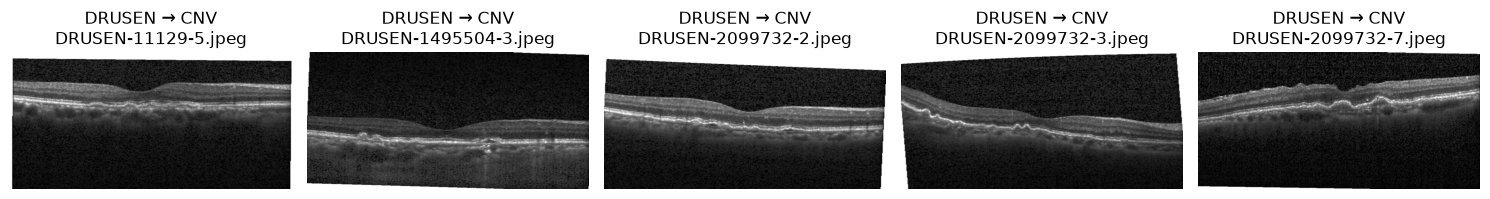

In [34]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

drusen_cnv_errors = [
    item[0][0]
    for item in misclassified
    if item[1] == 2 and item[2] == 0
]

print("DRUSEN → CNV errors:", len(drusen_cnv_errors))

plt.figure(figsize=(15, 8))

for i, image_path in enumerate(drusen_cnv_errors[:5]):

    image = Image.open(image_path).convert("L")

    plt.subplot(1, 5, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(f"DRUSEN → CNV\n{Path(image_path).name}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [35]:
print("model:", "model" in globals())
print("all_labels:", "all_labels" in globals())
print("all_preds:", "all_preds" in globals())
print("gradcam:", "gradcam" in globals())
print("show_gradcam:", "show_gradcam" in globals())


model: True
all_labels: True
all_preds: True
gradcam: True
show_gradcam: True


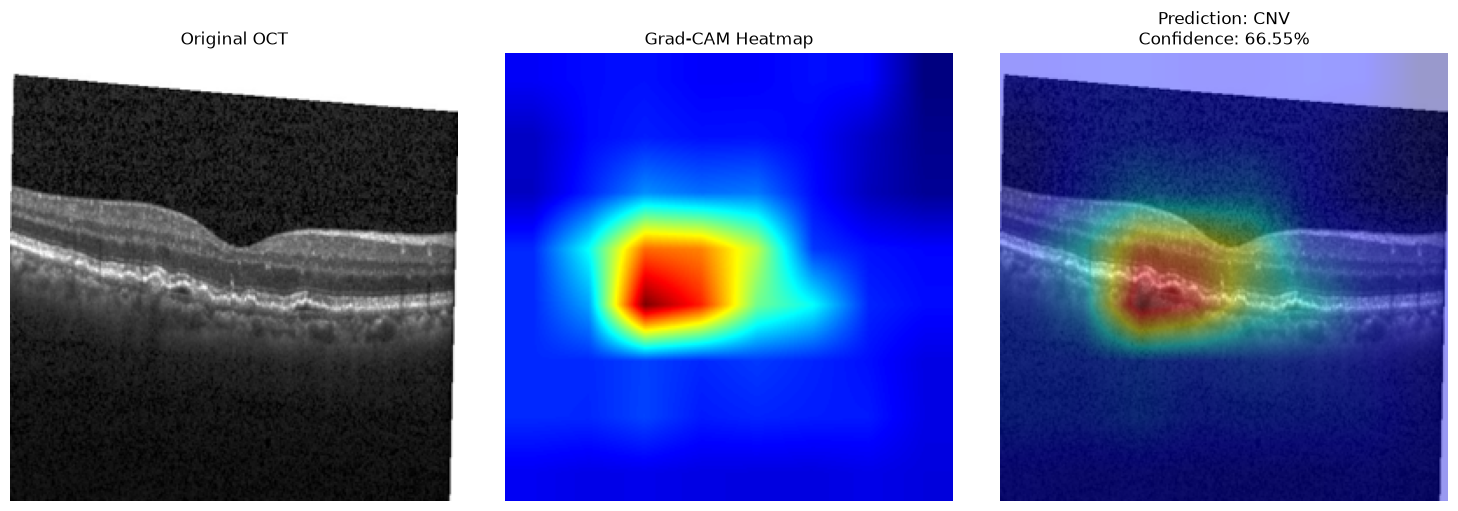

In [39]:
show_gradcam(drusen_cnv_errors[2])